In [63]:
import numpy as np
import pandas as pd
from scipy import signal, fft
import matplotlib.pyplot as plt

# Настройки эксперимента
T = 5.0          # длительность записи, секунд
f_high = 1000.0  # "очень частая" сетка времени (1000 отсчетов в секунду) — наш эталон
A5, A15 = 1.0, 1.0
alpha5, alpha15 = 0.2, 0.5

# 1. Эталонный сигнал (две затухающие синусоиды: 5 Гц и 15 Гц)
t = np.arange(0, T, 1.0 / f_high)
x_ref = (
    A5 * np.exp(-alpha5 * t) * np.sin(2 * np.pi * 5.0 * t)
    + A15 * np.exp(-alpha15 * t) * np.sin(2 * np.pi * 15.0 * t)
)

# 2. Помеха 0.5 - 2 Гц (50% от амплитуды сигнала)
rng = np.random.default_rng(42)
sos = signal.butter(4, [0.5, 2.0], btype="bandpass", fs=f_high, output="sos")
noise = signal.sosfiltfilt(sos, rng.standard_normal(len(t)))
noise = noise / np.max(np.abs(noise)) * (0.5 * np.max(np.abs(x_ref)))

# Сигнал на входе АЦП (сигнал + помеха)
y_in = x_ref + noise
y_max = float(np.max(np.abs(y_in)))

print("Шаг 1 готов! Длина сигнала:", len(t), "точек")

Шаг 1 готов! Длина сигнала: 5000 точек


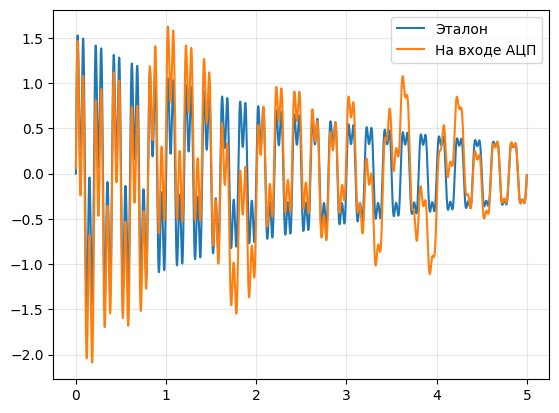

In [66]:
plt.plot(t, x_ref, label="Эталон")
plt.plot(t, y_in, label="На входе АЦП")
plt.legend()
plt.grid(alpha=0.3)

In [77]:
def adc_and_sinc(t_hi, y_hi, Fs, b):
    Ts = 1.0 / Fs
    t_s = np.arange(0, t_hi[-1], Ts)         # моменты взятия редких отсчетов
    y_s = np.interp(t_s, t_hi, y_hi)        # сами редкие отсчеты

    # Равномерное квантование на 2^b уровней
    step = (2.0 * y_max) / (2**b - 1)
    y_q = np.round(np.clip(y_s, -y_max, y_max) / step) * step

    # Восстановление по теореме Котельникова (своя sinc-функция)
    u = (t_hi[:, None] - t_s[None, :]) / Ts
    pi_u = np.pi * u
    sinc_mat = np.where(np.abs(pi_u) < 1e-12, 1.0, np.sin(pi_u) / np.where(np.abs(pi_u) < 1e-12, 1.0, pi_u))
    y_rec = sinc_mat @ y_q
    return t_s, y_q, y_rec

def get_ratio(sig, fs):
    n_fft = 16384
    spec = np.abs(fft.rfft(sig, n=n_fft)) * (2.0 / len(sig))
    freqs = fft.rfftfreq(n_fft, d=1.0 / fs)
    a5 = np.max(spec[(freqs >= 3.5) & (freqs <= 6.5)])
    a15 = np.max(spec[(freqs >= 13.5) & (freqs <= 16.5)])
    return a5 / (a15 + 1e-12), freqs, spec

ratio_ref, f_ref, s_ref = get_ratio(x_ref, f_high)
print("Шаг 2 готов! Эталонное отношение A5/A15:", round(ratio_ref, 4))

Шаг 2 готов! Эталонное отношение A5/A15: 1.7287


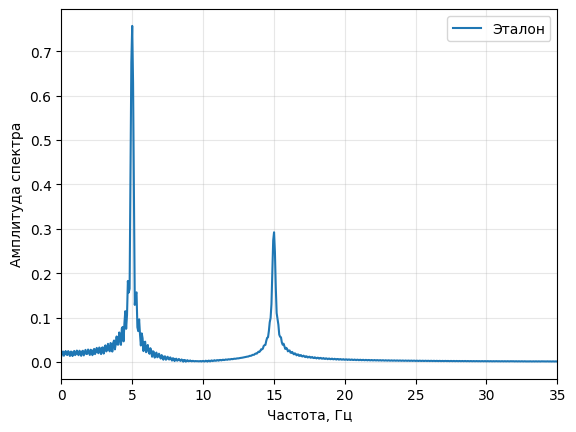

In [68]:
plt.plot(f_ref, s_ref, label="Эталон")
plt.xlim(0, 35)
plt.xlabel("Частота, Гц")
plt.ylabel("Амплитуда спектра")
plt.legend()
plt.grid(alpha=0.3)

In [82]:
K_list = [4.0, 2.0, 1.0, 0.7, 0.5]
b_list = [8, 10, 12, 16, 20]
max_err = 10.0

rows = []
rec_examples = {}

for K in K_list:
    Fs = K * 2.0 * 15.0  # при K=1.0 частота дискретизации равна 2 * 15 = 30 Гц
    for b in b_list:
        t_s, y_q, y_rec = adc_and_sinc(t, y_in, Fs, b)
        r_rec, _, _ = get_ratio(y_rec, f_high)
        err = abs(r_rec - ratio_ref) / ratio_ref * 100.0

        rows.append({
            "K": K, "Fs": Fs, "b": b,
            "Fs_b": Fs * b,
            "error_pct": round(err, 2)
        })
        if b == 20:
            rec_examples[K] = y_rec

df = pd.DataFrame(rows)
df.to_csv("results.csv", index=False)

# Отмечаем точки Парето-фронта (минимизируем и error_pct, и Fs_b)
pareto = []
for _, r1 in df.iterrows():
    worse_than_some = (
        (df["error_pct"] <= r1["error_pct"])
        & (df["Fs_b"] <= r1["Fs_b"])
        & ((df["error_pct"] < r1["error_pct"]) | (df["Fs_b"] < r1["Fs_b"]))
    ).any()
    pareto.append(not worse_than_some)
df["pareto"] = pareto

best = df[df["pareto"] & (df["error_pct"] <= max_err)].sort_values("Fs_b").iloc[0]
print("Оптимальная точка:", best.to_dict())
print("\nТаблица ошибок (%):")
print(df.pivot(index="K", columns="b", values="error_pct"))

Оптимальная точка: {'K': 2.0, 'Fs': 60.0, 'b': 8, 'Fs_b': 480.0, 'error_pct': 0.02, 'pareto': True}

Таблица ошибок (%):
b          8         10        12        16        20
K                                                    
0.5  30838.29  31036.13  31036.17  31003.25  31005.48
0.7  33498.82  34043.65  34290.44  34397.11  34396.44
1.0   8315.18   8332.63   8176.96   8139.63   8142.97
2.0      0.02      0.11      0.11      0.11      0.11
4.0      0.09      0.12      0.10      0.10      0.10


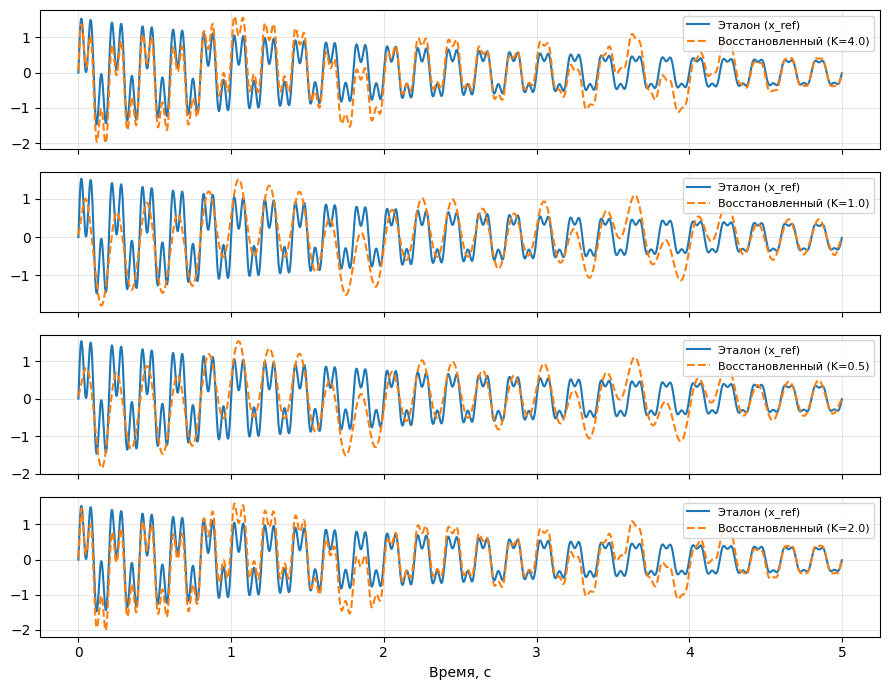

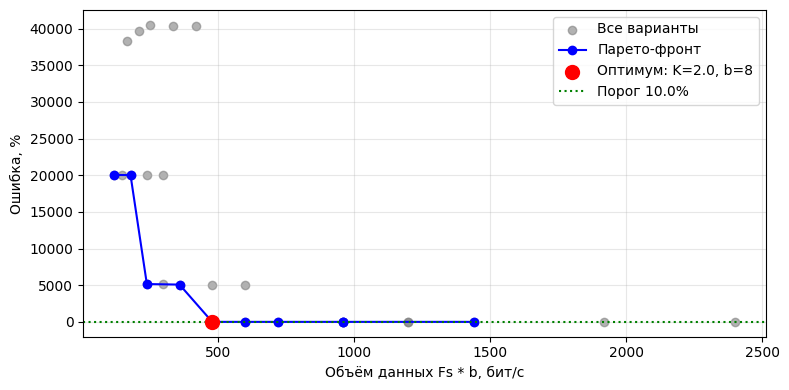

In [72]:
# График 1: Эталон vs восстановленный сигнал
fig, axs = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for ax, k_val in zip(axs, [4.0, 1.0, 0.5, 2.0]):
    ax.plot(t, x_ref, label="Эталон (x_ref)")
    # ax.plot(t, y_in, color="gray", alpha=0.35, linewidth=0.9, label="Вход с шумом (y_in)")
    ax.plot(t, rec_examples[k_val], "--", label=f"Восстановленный (K={k_val})")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)
axs[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.savefig("fig1_signals.png", dpi=150)
plt.show()

# График 2: Парето-фронт
plt.figure(figsize=(8, 4))
plt.scatter(df["Fs_b"], df["error_pct"], color="gray", alpha=0.6, label="Все варианты")
pf = df[df["pareto"]].sort_values("Fs_b")
plt.plot(pf["Fs_b"], pf["error_pct"], "bo-", label="Парето-фронт")
plt.scatter([best["Fs_b"]], [best["error_pct"]], color="red", s=100, zorder=5,
            label=f"Оптимум: K={best['K']}, b={int(best['b'])}")
plt.axhline(max_err, color="green", ls=":", label=f"Порог {max_err}%")
plt.xlabel("Объём данных Fs * b, бит/с")
plt.ylabel("Ошибка, %")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_pareto.png", dpi=150)
plt.show()

In [74]:
best


,5
K,2.0
Fs,60.0
b,8
Fs_b,480.0
error_pct,0.12
pareto,True


In [42]:
# Скачать один JSON-файл в текущую директорию (/content)
!wget -O config.json https://raw.githubusercontent.com/Avatar-cod/Kurs_OCOS/refs/heads/main/config.json

--2026-11-24 07:27:48--  https://raw.githubusercontent.com/Avatar-cod/Kurs_OCOS/refs/heads/main/config.json
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 291 [text/plain]
Saving to: ‘config.json’

config.json         100%[===================>]     291  --.-KB/s    in 0s      

2026-11-24 07:27:48 (5.62 MB/s) - ‘config.json’ saved [291/291]



Максимальное расхождение ручной sinc с np.sinc: 0.00e+00
Оптимальная точка: {'K': 2.0, 'Fs': 60.0, 'b': 8, 'Fs_b': 480.0, 'ratio_ref': 1.7287, 'ratio_rec': 1.7342, 'error_pct': 0.32, 'pareto': True}

Таблица ошибок (%):
b          8         10        12        16        20
K                                                    
0.5  31271.06  30884.48  31003.48  31005.93  31005.39
0.7  35028.02  34675.96  34502.72  34398.68  34396.91
1.0   7819.42   8217.40   8147.07   8143.79   8143.35
2.0      0.32      0.13      0.11      0.11      0.11
4.0      0.18      0.11      0.10      0.10      0.10


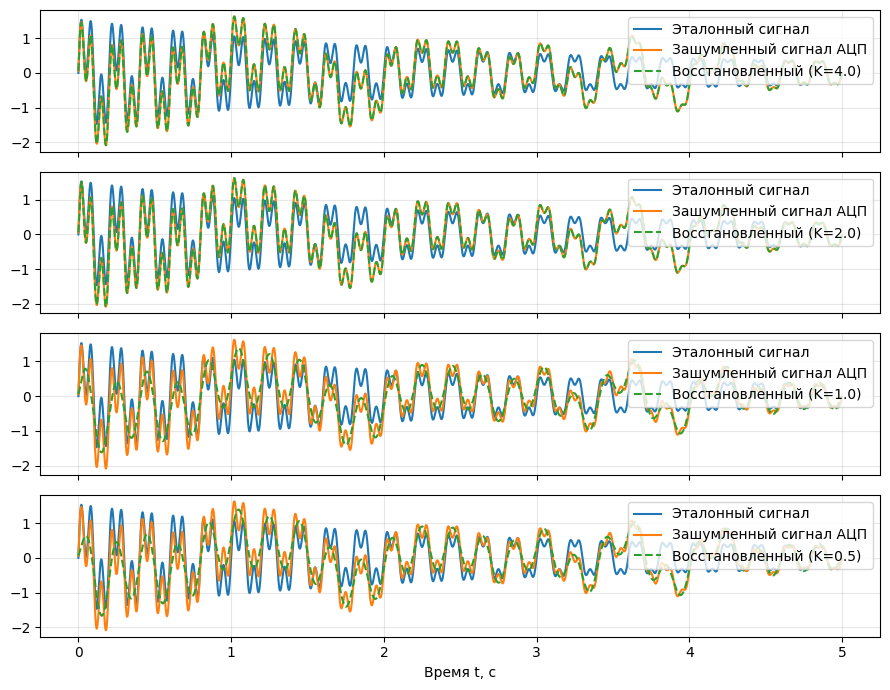

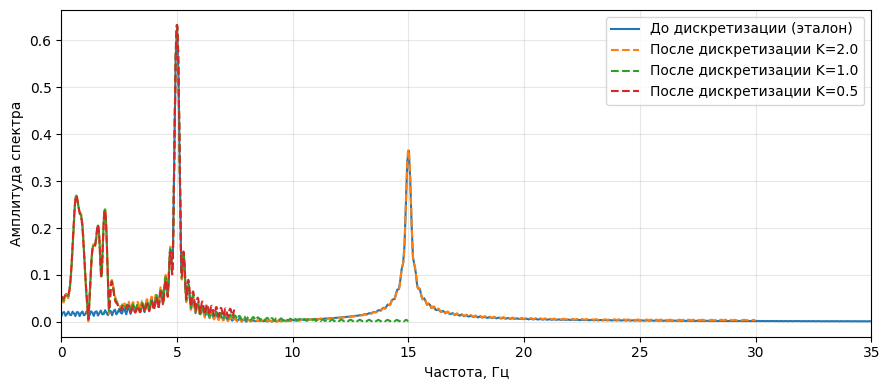

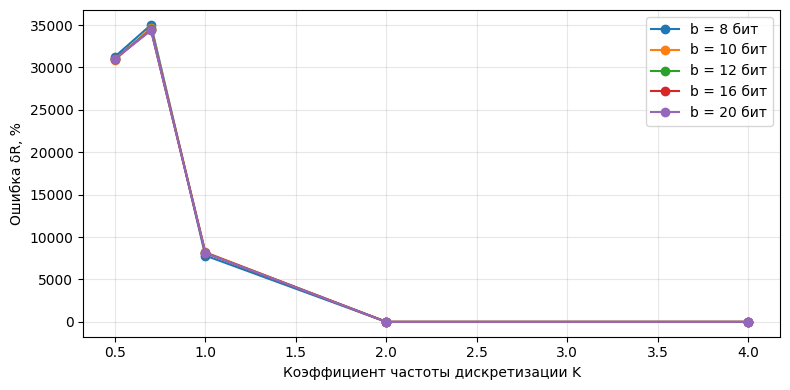

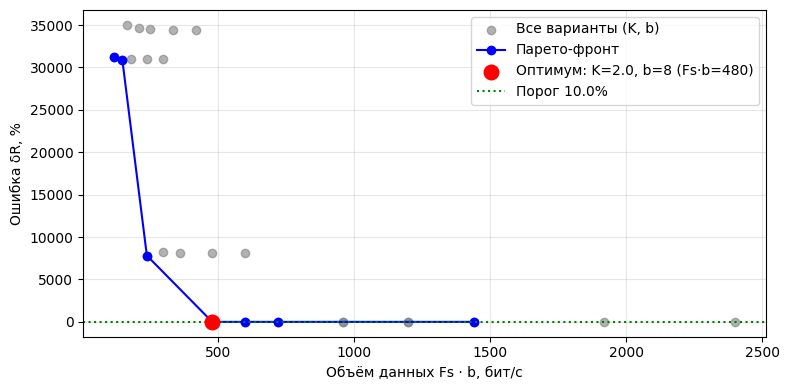

In [92]:
import argparse
import json
import urllib.request
import numpy as np
import pandas as pd
from scipy import signal, fft
import matplotlib.pyplot as plt



def load_config(default_path="/content/config.json"):
    parser = argparse.ArgumentParser(add_help=False)
    parser.add_argument("--config", type=str, default=default_path, help="Путь к локальному config.json")
    parser.add_argument("--max-err", type=float, default=None, help="Переопределить порог ошибки (%)")
    args, _ = parser.parse_known_args()

    with open(args.config, "r", encoding="utf-8") as f:
        cfg = json.load(f)

    if args.max_err is not None:
        cfg["max_err_pct"] = args.max_err
    return cfg


def generate_signals(cfg):
    rng = np.random.default_rng(cfg.get("seed", 42))
    t = np.arange(0, cfg["T"], 1.0 / cfg["f_high"])

    # Полезный сигнал: две затухающие фазы (5 Гц и 15 Гц)
    x_ref = (
        cfg["A5"] * np.exp(-cfg["alpha5"] * t) * np.sin(2 * np.pi * 5.0 * t)
        + cfg["A15"] * np.exp(-cfg["alpha15"] * t) * np.sin(2 * np.pi * 15.0 * t)
    )

    # Микросейсмический фон 0.5 - 2 Гц, амплитуда 50% от сигнала
    sos = signal.butter(
        4,
        [cfg["noise_low_hz"], cfg["noise_high_hz"]],
        btype="bandpass",
        fs=cfg["f_high"],
        output="sos",
    )
    noise = signal.sosfiltfilt(sos, rng.standard_normal(len(t)))
    noise = noise / (np.max(np.abs(noise)) + 1e-12) * (cfg["noise_amp_ratio"] * np.max(np.abs(x_ref)))

    y_in = x_ref + noise
    return t, x_ref, y_in


def quantize_uniform(y_s, b, y_max):
    levels = 2 ** int(b)
    step = (2.0 * y_max) / (levels - 1)
    y_clipped = np.clip(y_s, -y_max, y_max)
    return np.round((y_clipped + y_max) / step) * step - y_max


def custom_sinc_interp(t_hi, t_s, y_q, Ts):
    """Собственная реализация sinc-интерполяции по теореме Котельникова."""
    u = (t_hi[:, None] - t_s[None, :]) / Ts
    pi_u = np.pi * u
    small = np.abs(pi_u) < 1e-12
    safe_pi_u = np.where(small, 1.0, pi_u)
    sinc_mat = np.where(small, 1.0, np.sin(pi_u) / safe_pi_u)
    return sinc_mat @ y_q


def verify_sinc(t_hi, t_s, y_q, Ts, y_rec_custom):
    """Верификация ручной sinc-интерполяции против встроенного np.sinc."""
    u = (t_hi[:, None] - t_s[None, :]) / Ts
    y_rec_ref = np.sinc(u) @ y_q
    max_diff = float(np.max(np.abs(y_rec_custom - y_rec_ref)))
    return max_diff


def get_spectrum(sig, fs):
    n_fft = 16384
    spec = np.abs(fft.rfft(sig, n=n_fft)) * (2.0 / len(sig))
    freqs = fft.rfftfreq(n_fft, d=1.0 / fs)
    return freqs, spec


def estimate_ratio_a5_a15(sig, fs):
    freqs, spec = get_spectrum(sig, fs)
    a5 = np.max(spec[(freqs >= 3.5) & (freqs <= 6.5)])
    a15 = np.max(spec[(freqs >= 13.5) & (freqs <= 16.5)])
    ratio = a5 / (a15 + 1e-12)
    return ratio, freqs, spec


def find_pareto_front(df):
    pareto = []
    for _, r1 in df.iterrows():
        dominated = (
            (df["error_pct"] <= r1["error_pct"])
            & (df["Fs_b"] <= r1["Fs_b"])
            & ((df["error_pct"] < r1["error_pct"]) | (df["Fs_b"] < r1["Fs_b"]))
        ).any()
        pareto.append(not dominated)
    return pareto


def main():
    cfg = load_config()
    t, x_ref, y_in = generate_signals(cfg)
    y_max = float(np.max(np.abs(y_in)))
    f_max = 15.0  # верхняя частота полезного сигнала (15 Гц)

    ratio_ref, f_ref, s_ref = estimate_ratio_a5_a15(x_ref, cfg["f_high"])

    rows = []
    rec_examples = {}
    spec_examples = {}
    sinc_diff = None

    for K in cfg["K_values"]:
        Fs = K * 2.0 * f_max
        Ts = 1.0 / Fs
        t_s = np.arange(0, t[-1], Ts)
        y_s = np.interp(t_s, t, y_in)

        for b in cfg["b_values"]:
            y_q = quantize_uniform(y_s, b, y_max)
            y_rec = custom_sinc_interp(t, t_s, y_q, Ts)

            if sinc_diff is None and K == cfg["K_values"][0] and b == cfg["b_values"][-1]:
                sinc_diff = verify_sinc(t, t_s, y_q, Ts, y_rec)

            r_rec, _, _ = estimate_ratio_a5_a15(y_rec, cfg["f_high"])
            err_pct = abs(r_rec - ratio_ref) / (ratio_ref + 1e-12) * 100.0

            rows.append({
                "K": K,
                "Fs": Fs,
                "b": b,
                "Fs_b": Fs * b,
                "ratio_ref": round(float(ratio_ref), 4),
                "ratio_rec": round(float(r_rec), 4),
                "error_pct": round(float(err_pct), 2),
            })

            if b == max(cfg["b_values"]):
                rec_examples[K] = y_rec
                spec_examples[K] = get_spectrum(y_q, Fs)

    df = pd.DataFrame(rows)
    df["pareto"] = find_pareto_front(df)
    df.to_csv("results.csv", index=False)

    valid = df[df["pareto"] & (df["error_pct"] <= cfg["error_threshold_pct"])]
    best = valid.sort_values("Fs_b").iloc[0] if len(valid) else None

    print(f"Максимальное расхождение ручной sinc с np.sinc: {sinc_diff:.2e}")
    print("Оптимальная точка:", best.to_dict() if best is not None else "Нет точек в допуске")
    print("\nТаблица ошибок (%):")
    print(df.pivot(index="K", columns="b", values="error_pct"))

    # 1. График: Эталон vs восстановленный для трёх K (4.0, 1.0, 0.5)
    fig, axs = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
    for ax, k_val in zip(axs, [4.0, 2.0, 1.0, 0.5]):
        ax.plot(t, x_ref, label="Эталонный сигнал")
        ax.plot(t, y_in, label="Зашумленный сигнал АЦП")
        ax.plot(t, rec_examples[k_val], "--", label=f"Восстановленный (K={k_val})")
        ax.legend(loc="upper right")
        ax.grid(alpha=0.3)
    axs[-1].set_xlabel("Время t, с")
    plt.tight_layout()
    plt.savefig("fig1_signals.png", dpi=150)
    plt.show()

    # 2. График: Спектры до и после дискретизации
    plt.figure(figsize=(9, 4))
    plt.plot(f_ref, s_ref, label="До дискретизации (эталон)")
    for k_val in [2.0, 1.0, 0.5]:
        fd, sd = spec_examples[k_val]
        plt.plot(fd, sd, "--", label=f"После дискретизации K={k_val}")
    plt.xlim(0, 35)
    plt.xlabel("Частота, Гц")
    plt.ylabel("Амплитуда спектра")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("fig2_spectra.png", dpi=150)
    plt.show()

    # 3. График: Зависимость ошибки от K и b
    plt.figure(figsize=(8, 4))
    for b_val in cfg["b_values"]:
        sub = df[df["b"] == b_val]
        plt.plot(sub["K"], sub["error_pct"], "o-", label=f"b = {b_val} бит")
    plt.xlabel("Коэффициент частоты дискретизации K")
    plt.ylabel("Ошибка δR, %")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("fig3_errors.png", dpi=150)
    plt.show()

    # 4. График: Парето-фронт
    plt.figure(figsize=(8, 4))
    plt.scatter(df["Fs_b"], df["error_pct"], color="gray", alpha=0.6, label="Все варианты (K, b)")
    pf = df[df["pareto"]].sort_values("Fs_b")
    plt.plot(pf["Fs_b"], pf["error_pct"], "bo-", label="Парето-фронт")
    if best is not None:
        plt.scatter(
            [best["Fs_b"]],
            [best["error_pct"]],
            color="red",
            s=110,
            zorder=5,
            label=f"Оптимум: K={best['K']}, b={int(best['b'])} (Fs·b={best['Fs_b']:.0f})",
        )
    plt.axhline(cfg["error_threshold_pct"], color="green", ls=":", label=f"Порог {cfg['error_threshold_pct']}%")
    plt.xlabel("Объём данных Fs · b, бит/с")
    plt.ylabel("Ошибка δR, %")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("fig4_pareto.png", dpi=150)
    plt.show()


if __name__ == "__main__":
    main()